# Lab 5 — Motor parameter identification

Wheel 1, M4/E4. Source: `Husanboy_motor_data.txt`. Columns: **PWM percent, time_ms, angle_deg, battery_voltage_V**. PWM was reconstructed from 41 timer-reset runs and the QRS loop `pwm = -100; pwm <= 100; pwm = pwm + 5`; no original time, angle, or voltage values were changed. The unmodified three-column recording is retained in `motor_data/Husanboy_motor_data_raw.txt`.

Only one drive wheel was recorded, so the required two-wheel comparison remains unavailable. The collection diagram writes to disk and reads the battery inside its sampling loop; this differs from the README's memory-buffered collection method. The recorded loading condition is not documented. This report follows the course notebook using `optimize.curve_fit`, its first-timestamp SI conversion, and `odeint`.


## 1. Load measurements and convert to SI

For each run, shift time to its first sample and convert milliseconds to seconds and degrees to radians, as in the course notebook. Voltage for the step is approximated by `U = PWM/100 * mean(battery_voltage)`. First-sample time shifting omits the initial command-to-sample delay; fitted response times therefore depend on this timing convention.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint
from IPython.display import Markdown, display

DATA = Path("Husanboy_motor_data.txt")
data = np.loadtxt(DATA, delimiter=",")
assert data.shape[1] == 4 and np.isfinite(data).all()
assert np.array_equal(np.unique(data[:, 0]), np.arange(-100, 101, 5))
traces = {}
voltage = {}
battery = {}
intervals = []
for pwm in range(-100, 101, 5):
    run = data[data[:, 0] == pwm]
    assert np.all(np.diff(run[:, 1]) > 0)
    time = (run[:, 1] - run[0, 1]) / 1000
    angle = run[:, 2] * np.pi / 180
    traces[pwm] = (time, angle)
    battery[pwm] = np.mean(run[:, 3])
    voltage[pwm] = pwm / 100 * battery[pwm]
    intervals.extend(np.diff(run[:, 1]))
display(Markdown(
    f"**{len(data):,} samples, 41 PWM settings.** "
    f"Actual sample spacing: median {np.median(intervals):.1f} ms, "
    f"range {np.min(intervals):.1f}–{np.max(intervals):.1f} ms. "
    f"Battery readings: {data[:,3].min():.3f}–{data[:,3].max():.3f} V."))


**1,367 samples, 41 PWM settings.** Actual sample spacing: median 59.4 ms, range 54.1–170.4 ms. Battery readings: 11.921–12.038 V.

## 2. Fit T_m and steady-state speed at every power setting

Use the course equation `theta(t) = speed*t - speed*T_m + speed*T_m*exp(-t/T_m)`. As in its example, the initial guess for T_m is 0.4 s; the initial speed is ±8 rad/s according to direction. Positive T_m bounds prevent nonphysical fits. Parameters at a fitting bound are unresolved; no-motion data cannot identify T_m. A large angle R² alone does not validate the acceleration model.


In [2]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)


results = []
fits = {}
for pwm, (time, angle) in traces.items():
    if np.ptp(angle) == 0:
        results.append(dict(pwm=pwm, T=None, speed=0.0, U=voltage[pwm],
                            samples=len(time), note="No motion; T unresolved"))
        continue
    try:
        popt, pcov = optimize.curve_fit(
            model, time, angle, p0=[8 if pwm > 0 else -8, 0.4],
            bounds=([-np.inf, 0.0001], [np.inf, 5.0]), maxfev=20000)
    except RuntimeError:
        results.append(dict(pwm=pwm, T=None, speed=None, U=voltage[pwm],
                            samples=len(time), note="Fit failed"))
        continue
    speed, T_m = popt
    boundary = T_m < 0.00011 or T_m > 4.99
    notes = []
    if boundary:
        notes.append("Fit at bound; unresolved")
    else:
        fits[pwm] = (popt, pcov)
        if T_m < np.median(np.diff(time)):
            notes.append("T below sample spacing")
        if T_m > 0.5:
            notes.append("Steady state uncertain")
    error = np.sum((angle-model(time,*popt))**2)
    r2 = 1-error/np.sum((angle-angle.mean())**2)
    if r2 < 0.99:
        notes.append("Model mismatch")
    results.append(dict(pwm=pwm, T=None if boundary else float(T_m),
                        speed=None if boundary else float(speed), U=voltage[pwm],
                        samples=len(time), note="; ".join(notes)))

lines = ["| PWM (%) | Samples | Battery (V) | Applied U (V) | T_m (s) | omega_ss (rad/s) | Note |",
         "|---:|---:|---:|---:|---:|---:|---|"]
for r in results:
    T = "—" if r["T"] is None else f'{r["T"]:.4f}'
    speed = "—" if r["speed"] is None else f'{r["speed"]:.3f}'
    lines.append(f'| {r["pwm"]} | {r["samples"]} | {battery[r["pwm"]]:.3f} | {r["U"]:.3f} | {T} | {speed} | {r["note"]} |')
display(Markdown("\n".join(lines)))


| PWM (%) | Samples | Battery (V) | Applied U (V) | T_m (s) | omega_ss (rad/s) | Note |
|---:|---:|---:|---:|---:|---:|---|
| -100 | 34 | 11.998 | -11.998 | 0.0075 | -14.941 | T below sample spacing |
| -95 | 26 | 12.003 | -11.403 | 0.0317 | -14.446 | T below sample spacing |
| -90 | 34 | 12.004 | -10.804 | 0.0478 | -13.598 | T below sample spacing |
| -85 | 34 | 11.996 | -10.196 | 0.0637 | -12.854 |  |
| -80 | 34 | 11.997 | -9.598 | 0.0769 | -12.531 |  |
| -75 | 34 | 12.000 | -9.000 | 0.0849 | -12.060 |  |
| -70 | 32 | 12.002 | -8.401 | 0.1103 | -11.308 |  |
| -65 | 29 | 12.005 | -7.803 | 0.1381 | -10.539 |  |
| -60 | 33 | 11.998 | -7.199 | 0.1369 | -10.250 |  |
| -55 | 34 | 11.995 | -6.597 | 0.1825 | -9.733 |  |
| -50 | 34 | 11.997 | -5.998 | 0.1579 | -9.379 |  |
| -45 | 34 | 11.998 | -5.399 | 0.1832 | -9.004 |  |
| -40 | 34 | 12.001 | -4.800 | 0.1808 | -8.677 |  |
| -35 | 33 | 12.002 | -4.201 | 0.1800 | -8.246 |  |
| -30 | 34 | 12.000 | -3.600 | 0.2258 | -7.220 |  |
| -25 | 33 | 11.997 | -2.999 | 0.2431 | -6.610 |  |
| -20 | 34 | 11.997 | -2.399 | 0.2671 | -5.914 |  |
| -15 | 34 | 11.997 | -1.800 | 0.2734 | -5.189 |  |
| -10 | 31 | 12.000 | -1.200 | 0.2982 | -4.286 |  |
| -5 | 34 | 12.005 | -0.600 | 0.4271 | -2.243 |  |
| 0 | 34 | 12.001 | 0.000 | — | 0.000 | No motion; T unresolved |
| 5 | 33 | 11.998 | 0.600 | — | — | Fit at bound; unresolved; Model mismatch |
| 10 | 34 | 11.997 | 1.200 | 0.3158 | 4.335 |  |
| 15 | 32 | 11.994 | 1.799 | 0.2544 | 5.235 |  |
| 20 | 34 | 12.000 | 2.400 | 0.2581 | 6.135 |  |
| 25 | 34 | 11.995 | 2.999 | 0.2343 | 6.858 |  |
| 30 | 34 | 12.000 | 3.600 | 0.2136 | 7.445 |  |
| 35 | 34 | 11.992 | 4.197 | 0.2020 | 8.633 |  |
| 40 | 33 | 11.997 | 4.799 | 0.1796 | 9.000 |  |
| 45 | 34 | 11.992 | 5.396 | 0.1785 | 9.476 |  |
| 50 | 34 | 11.988 | 5.994 | 0.1717 | 9.907 |  |
| 55 | 34 | 11.988 | 6.593 | 0.1703 | 10.228 |  |
| 60 | 34 | 11.992 | 7.195 | 0.1587 | 10.886 |  |
| 65 | 34 | 11.994 | 7.796 | 0.1476 | 11.145 |  |
| 70 | 34 | 11.989 | 8.392 | 0.1199 | 12.036 |  |
| 75 | 33 | 11.990 | 8.993 | 0.0874 | 12.877 |  |
| 80 | 34 | 11.985 | 9.588 | 0.0849 | 13.382 |  |
| 85 | 33 | 11.986 | 10.188 | 0.0831 | 13.825 |  |
| 90 | 34 | 11.989 | 10.790 | 0.0431 | 14.635 | T below sample spacing |
| 95 | 34 | 11.981 | 11.382 | 0.0355 | 15.593 | T below sample spacing |
| 100 | 34 | 11.982 | 11.982 | 0.0218 | 16.132 | T below sample spacing |

## 3. Speed versus actual voltage and fitted k_e

Fit the course model `omega_ss = U/k_e`, constrained through the origin, using all resolved moving runs. The slope of omega against U is **1/k_e**, so take its reciprocal. The result is an effective parameter of this simplified motor model, not an independent intrinsic back-EMF measurement. The plot also shows separate directional fits because forward and reverse can differ.

A stationary point marks an observed no-motion setting. The nearest moving settings bound the unresolved dead-zone thresholds; the interval between them must not be interpreted as entirely motionless.


**Effective k_e: 0.7027 V·s/rad** (all 39 resolved moving runs). Forward: 0.6808; reverse: 0.7261 V·s/rad. The origin fit is an approximation across nonlinear operating points.

No motion at PWM [0]. Motion occurs at -5% and +5%; thresholds remain unresolved within -0.600 to 0.600 V. Repeated starts are needed to establish a repeatable dead zone.

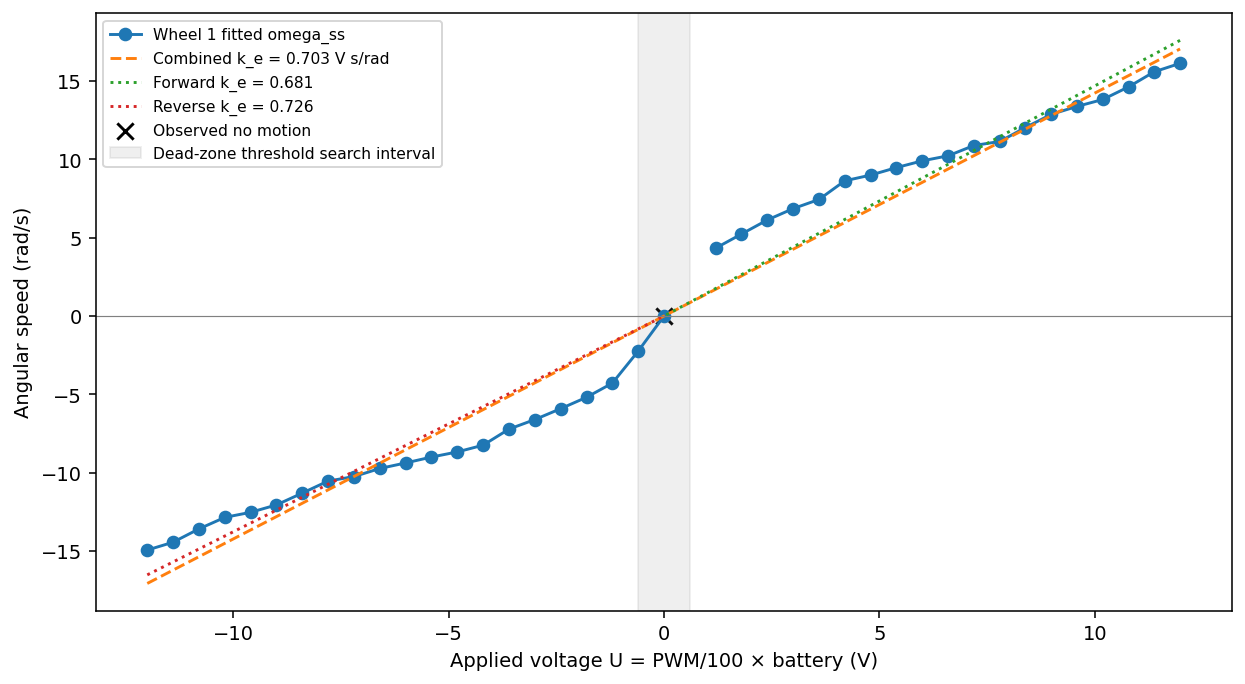

In [3]:
usable = [r for r in results if r["speed"] is not None and r["T"] is not None and r["pwm"] != 0]


def effective_ke(rows):
    U = np.array([r["U"] for r in rows])
    omega = np.array([r["speed"] for r in rows])
    if len(U) < 2:
        raise ValueError("Not enough resolved runs for voltage-speed fitting")
    slope = np.dot(U, omega) / np.dot(U, U)
    return 1 / slope


k_e = effective_ke(usable)
k_forward = effective_ke([r for r in usable if r["pwm"] > 0])
k_reverse = effective_ke([r for r in usable if r["pwm"] < 0])
display(Markdown(
    f"**Effective k_e: {k_e:.4f} V·s/rad** "
    f"(all {len(usable)} resolved moving runs). "
    f"Forward: {k_forward:.4f}; reverse: {k_reverse:.4f} V·s/rad. "
    "The origin fit is an approximation across nonlinear operating points."))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot([r["U"] for r in results],
        [np.nan if r["speed"] is None else r["speed"] for r in results],
        "o-", label="Wheel 1 fitted omega_ss")
u = np.linspace(min(voltage.values()), max(voltage.values()), 200)
ax.plot(u, u/k_e, "--", label=f"Combined k_e = {k_e:.3f} V s/rad")
ax.plot(u[u >= 0], u[u >= 0]/k_forward, ":", label=f"Forward k_e = {k_forward:.3f}")
ax.plot(u[u <= 0], u[u <= 0]/k_reverse, ":", label=f"Reverse k_e = {k_reverse:.3f}")
stationary = [p for p, (t, angle) in traces.items() if np.ptp(angle) == 0]
if stationary:
    ax.scatter([voltage[p] for p in stationary], np.zeros(len(stationary)),
               marker="x", s=70, color="black", label="Observed no motion")
negative_motion = [p for p in traces if p < 0 and p not in stationary]
positive_motion = [p for p in traces if p > 0 and p not in stationary]
if negative_motion and positive_motion:
    lower, upper = max(negative_motion), min(positive_motion)
    ax.axvspan(voltage[lower], voltage[upper], alpha=0.12, color="gray",
               label="Dead-zone threshold search interval")
    display(Markdown(
        f"No motion at PWM {stationary}. Motion occurs at {lower}% and +{upper}%; "
        f"thresholds remain unresolved within {voltage[lower]:.3f} to {voltage[upper]:.3f} V. "
        "Repeated starts are needed to establish a repeatable dead zone."))
ax.axhline(0, color="gray", linewidth=0.6)
ax.set(xlabel="Applied voltage U = PWM/100 × battery (V)", ylabel="Angular speed (rad/s)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## 4. Measured step response and simulated motor

Use the +100% run. As in the course notebook, the motor state is `[speed, angle]`. Integrate from `[0, 0]` with `odeint` and plot measured angle, the fitted angle equation, and the simulated angle together. For this operating point, set `k_e_step = U / fitted_speed`, so the simulation uses the step's identified steady speed. This local effective coefficient can differ from the combined voltage-speed coefficient because the motor is not globally linear. The overlay is an in-sample fit check.


+100%: T_m = 0.0218 s, omega_ss = 16.132 rad/s, U = 11.982 V, local k_e = 0.7427 V·s/rad.

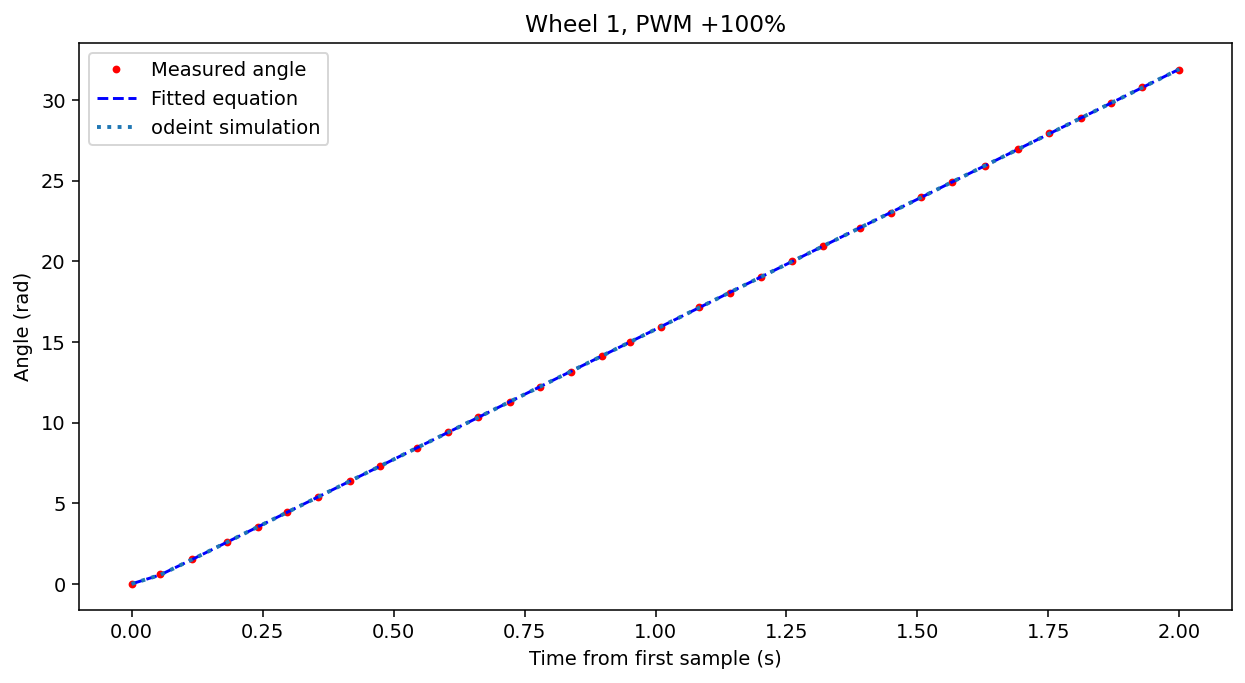

In [4]:
time, angle = traces[100]
popt, pcov = fits[100]
speed_ss, T_m = popt
u = voltage[100]
k_e_step = u / speed_ss


def motor(state, t):
    speed, angle = state
    return np.array([-speed/T_m + u/(T_m*k_e_step), speed])


y = odeint(motor, [0, 0], time, rtol=1e-9, atol=1e-10)
equation = model(time, popt[0], popt[1])
display(Markdown(
    f"+100%: T_m = {T_m:.4f} s, omega_ss = {speed_ss:.3f} rad/s, "
    f"U = {u:.3f} V, local k_e = {k_e_step:.4f} V·s/rad."))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(time, angle, "r.", label="Measured angle")
ax.plot(time, equation, "b--", label="Fitted equation")
ax.plot(time, y[:, 1], ":", linewidth=2, label="odeint simulation")
ax.set(xlabel="Time from first sample (s)", ylabel="Angle (rad)", title="Wheel 1, PWM +100%")
ax.legend()
fig.tight_layout()
plt.show()


In [5]:
forward = next(r for r in results if r["pwm"] == 100)
reverse = next(r for r in results if r["pwm"] == -100)
difference = 100*(abs(forward["speed"])/abs(reverse["speed"])-1)
display(Markdown("## Discussion\n\n"
    "The first-order model captures the full-power angle response, but the nonlinear voltage-speed characteristic and low-power behavior limit one constant model across the whole sweep. "
    f"The fitted full-power forward speed magnitude is {difference:.1f}% higher than reverse for this wheel. "
    "Only M4/E4 was recorded, so the difference between the two drive wheels cannot be measured. "
    "Unequal wheel speeds would change the commanded path and bias odometry predictions based on modeled speeds; encoder-based odometry also depends on geometry and slip. "
    "Slow sampling and file writing inside the collection loop limit the confidence of the startup-time estimates."))


## Discussion

The first-order model captures the full-power angle response, but the nonlinear voltage-speed characteristic and low-power behavior limit one constant model across the whole sweep. The fitted full-power forward speed magnitude is 8.0% higher than reverse for this wheel. Only M4/E4 was recorded, so the difference between the two drive wheels cannot be measured. Unequal wheel speeds would change the commanded path and bias odometry predictions based on modeled speeds; encoder-based odometry also depends on geometry and slip. Slow sampling and file writing inside the collection loop limit the confidence of the startup-time estimates.